# Forest Plot

**Family:** Scientific & clinical &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Scientific & clinical:* Specialised plots for statistics, biomedical research and model evaluation.

## Design purpose

Shows effect estimates (hazard ratio, odds ratio, mean difference) with confidence intervals for many subgroups or studies, aligned against a line of no effect. It is the core figure of meta-analyses and trial subgroup analyses.

## When to use

- Show a meta-analysis that pools results from several studies
- Check the consistency of a treatment effect across pre-specified subgroups
- Present regression coefficients or odds ratios with their CIs

## Avoid when

- There are only one or two estimates (state them in text)
- Estimates are on different scales (normalize first)

## Alternatives

- Coefficient (dot-and-whisker) plot
- Table of estimates

## Design tips

- Plot ratios on a log scale so that 0.5 and 2 are equidistant from 1
- Size the squares by weight or sample size, and show the pooled estimate as a diamond
- Print the numeric estimate and CI in a column beside the plot

## Example

Hazard ratios (new treatment vs. control) for overall survival across patient subgroups (synthetic).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rows = [  # label, HR, lower, upper, n   (None = section header)
    ("Overall", 0.72, 0.60, 0.86, 840),
    ("Age", None, None, None, None),
    ("  < 65 years", 0.68, 0.53, 0.87, 470), ("  ≥ 65 years", 0.78, 0.59, 1.03, 370),
    ("Sex", None, None, None, None),
    ("  Female", 0.70, 0.54, 0.91, 410), ("  Male", 0.74, 0.57, 0.96, 430),
    ("ECOG status", None, None, None, None),
    ("  0", 0.65, 0.50, 0.85, 500), ("  1", 0.83, 0.62, 1.11, 340),
    ("Biomarker", None, None, None, None),
    ("  Positive", 0.55, 0.42, 0.72, 380), ("  Negative", 0.92, 0.72, 1.18, 460),
]
df = pd.DataFrame(rows, columns=["label", "hr", "lo", "hi", "n"])
df

,label,hr,lo,hi,n
0,Overall,0.72,0.60,0.86,840.0
1,Age,NaN,NaN,NaN,NaN
2,< 65 years,0.68,0.53,0.87,470.0
3,≥ 65 years,0.78,0.59,1.03,370.0
4,Sex,NaN,NaN,NaN,NaN
5,Female,0.70,0.54,0.91,410.0
6,Male,0.74,0.57,0.96,430.0
7,ECOG status,NaN,NaN,NaN,NaN
8,0,0.65,0.50,0.85,500.0
9,1,0.83,0.62,1.11,340.0


### Plot

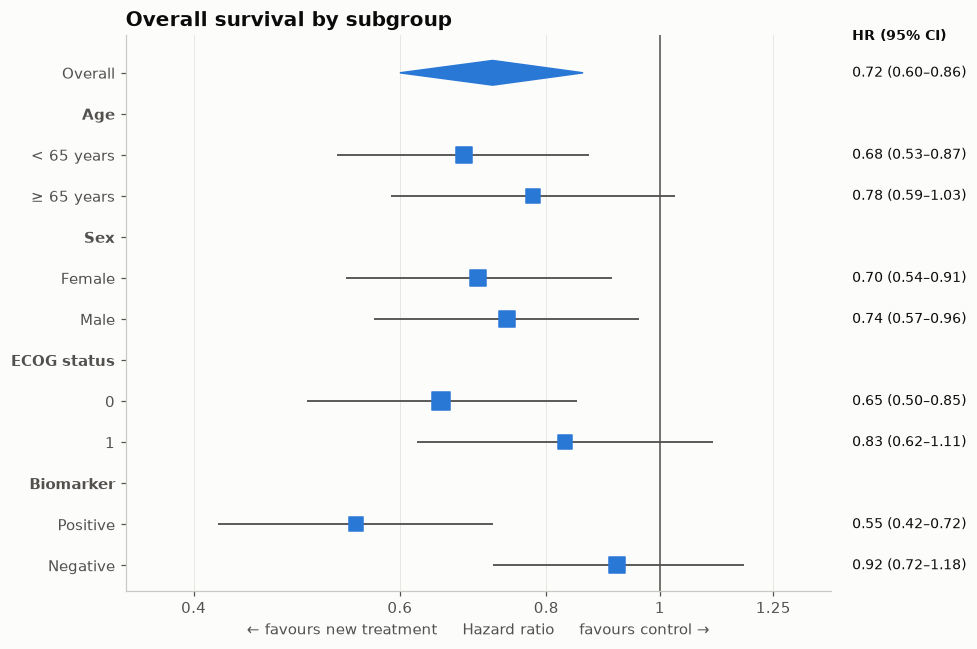

In [3]:
fig, ax = plt.subplots(figsize=(9, 6))
y = np.arange(len(df))[::-1]
for yi, r in zip(y, df.itertuples()):
    if pd.isna(r.hr):
        continue
    if r.label == "Overall":
        ax.fill([r.lo, r.hr, r.hi, r.hr], [yi, yi + 0.3, yi, yi - 0.3], color=PALETTE[0])
    else:
        ax.hlines(yi, r.lo, r.hi, color="#52514e", linewidth=1.2)
        ax.scatter(r.hr, yi, marker="s", s=r.n / 4, color=PALETTE[0], zorder=3)
    ax.text(1.03, yi, f"{r.hr:.2f} ({r.lo:.2f}–{r.hi:.2f})", transform=ax.get_yaxis_transform(),
            va="center", fontsize=9)
ax.axvline(1, color="#52514e", linewidth=1)
ax.set_xscale("log")
ax.set_xticks([0.4, 0.6, 0.8, 1, 1.25], ["0.4", "0.6", "0.8", "1", "1.25"])
ax.minorticks_off()
ax.set_xlim(0.35, 1.4)
ax.set_yticks(y, df["label"])
for lab, is_hdr in zip(ax.get_yticklabels(), df["hr"].isna()):
    if is_hdr:
        lab.set_fontweight("bold")
ax.grid(axis="y", visible=False)
ax.text(1.03, len(df) - 0.2, "HR (95% CI)", transform=ax.get_yaxis_transform(), fontweight="bold", fontsize=9)
ax.set_xlabel("← favours new treatment     Hazard ratio     favours control →")
ax.set_title("Overall survival by subgroup")
fig.tight_layout()
plt.show()

## How to read it

Each square is a subgroup's hazard ratio, and its line is the 95% CI. Squares left of 1 favour the new treatment. A CI that crosses 1 is not statistically significant. The diamond is the overall estimate.

---
Standalone script: [`forest_plot.py`](forest_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)